# BerlinStay Pricing Intelligence - V1 EDA
Exploratory analysis of the Berlin short-term-rental market (Inside Airbnb scrape 2026-09-19, CC BY 4.0).

**Reads from** the DuckDB star schema built by `python -m src.run_pipeline` (no raw CSVs here).
**Population:** unless stated, the *benchmark population*: listings with a price (10-1,000 EUR), average minimum stay under 28 nights.
**Honest limits:** occupancy and revenue are *estimates* (review-rate model); the calendar cannot separate booked from blocked nights and has no prices;
locations are anonymised (~150 m); one snapshot; only aggregates are shown, no host is identified.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd, duckdb
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
con = duckdb.connect(str(ROOT / "data" / "berlinstay.duckdb"), read_only=True)
IMG = ROOT / "docs" / "img"; IMG.mkdir(parents=True, exist_ok=True)
q = lambda sql: con.execute(sql).df()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "font.size": 10})
BLUE, GREY, ORANGE = "#2a6f97", "#8d99ae", "#e07a1f"
def save(fig, name): fig.savefig(IMG / f"{name}.png", bbox_inches="tight", dpi=130)

df = q('''
SELECT f.*, d.room_type, d.property_type, d.accommodates, d.capacity_band, d.bedrooms, d.beds, d.bathrooms, d.amenities_count,
       d.is_superhost, d.license_status, d.is_benchmark, d.listing_segment, d.latitude, d.longitude,
       n.district, n.neighbourhood, h.host_type
FROM mart.fact_listing f
JOIN mart.dim_listing d USING (listing_id)
JOIN mart.dim_neighbourhood n ON n.neighbourhood_key = d.neighbourhood_key
JOIN mart.dim_host_type h ON h.host_type_key = d.host_type_key
''')
b = df[df.is_benchmark].copy()
print(f"all listings {len(df):,} | benchmark population {len(b):,}")
df.listing_segment.value_counts().to_frame("listings")

all listings 12,376 | benchmark population 6,456


,listings
listing_segment,
Short-stay,6481
No price (inactive/unbookable),4219
Mid-term (28+ nights),1676


## 1. What is 'the market'? Segments

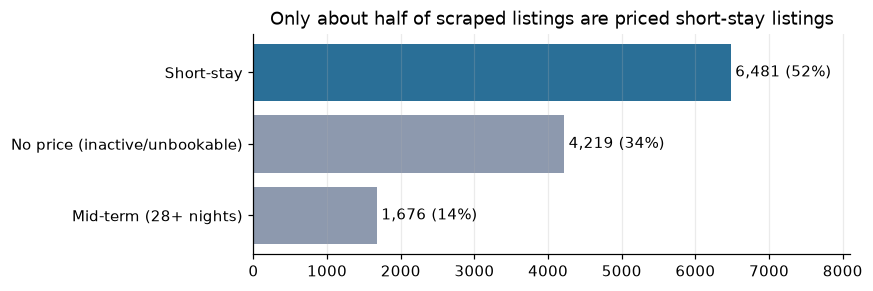

In [2]:
seg = df.listing_segment.value_counts()
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(seg.index[::-1], seg.values[::-1], color=[GREY, GREY, BLUE])
for i, v in enumerate(seg.values[::-1]): ax.text(v + 60, i, f"{v:,} ({v/len(df):.0%})", va="center")
ax.set_xlim(0, seg.max() * 1.25); ax.set_title("Only about half of scraped listings are priced short-stay listings"); ax.grid(axis="y", visible=False)
save(fig, "01_segments"); plt.show()

**Takeaway.** About a third of scraped listings have no price (not currently bookable) and about one in eight is mid-term (28+ nights).
Counting them as 'supply' or mixing them into price averages would misstate the tourist market, so every statistic below uses the benchmark population.

## 2. Price distribution and outlier handling

IQR rule on log-price would cut above 794 EUR and below 21 EUR


,n,mean,median,max
raw price (all priced),8157,167.6,129.5,10025.0
after 10-1000 EUR rule,8130,161.2,128.9,1000.0
benchmark population,6456,181.9,150.2,1000.0


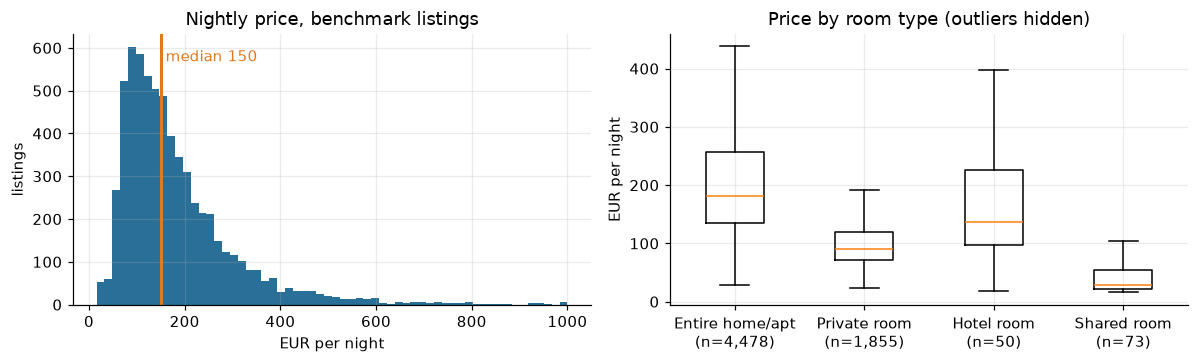

In [3]:
p = df.price_raw.dropna()
rule = df.price_eur.dropna()
def iqr_bounds(s): q1, q3 = s.quantile([.25, .75]); return q1 - 1.5*(q3-q1), q3 + 1.5*(q3-q1)
lo, hi = iqr_bounds(np.log(rule)); print(f"IQR rule on log-price would cut above {np.exp(hi):.0f} EUR and below {np.exp(lo):.0f} EUR")
cmp = pd.DataFrame({
  "n": [len(p), len(rule), len(b)],
  "mean": [p.mean(), rule.mean(), b.price_eur.mean()],
  "median": [p.median(), rule.median(), b.price_eur.median()],
  "max": [p.max(), rule.max(), b.price_eur.max()]}, index=["raw price (all priced)", "after 10-1000 EUR rule", "benchmark population"]).round(1)
display(cmp)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(b.price_eur, bins=60, color=BLUE); ax[0].axvline(b.price_eur.median(), color=ORANGE, lw=2)
ax[0].set(title="Nightly price, benchmark listings", xlabel="EUR per night", ylabel="listings"); ax[0].text(b.price_eur.median()+10, ax[0].get_ylim()[1]*.9, f"median {b.price_eur.median():.0f}", color=ORANGE)
order = ["Entire home/apt", "Private room", "Hotel room", "Shared room"]
ax[1].boxplot([b[b.room_type == r].price_eur for r in order], tick_labels=[f"{r}\n(n={int((b.room_type==r).sum()):,})" for r in order], showfliers=False)
ax[1].set(title="Price by room type (outliers hidden)", ylabel="EUR per night"); plt.tight_layout(); save(fig, "02_price_distribution"); plt.show()

**Takeaway.** Price is strongly right-skewed (a few luxury listings), so the **median**, not the mean, is the honest benchmark.
The fixed 10-1,000 EUR rule removes only a handful of listings (27 above 1,000) and is easier to explain than a statistical cut; flagged rows are kept in the database, never deleted.

## 3. What correlates with price? (Spearman, benchmark listings)

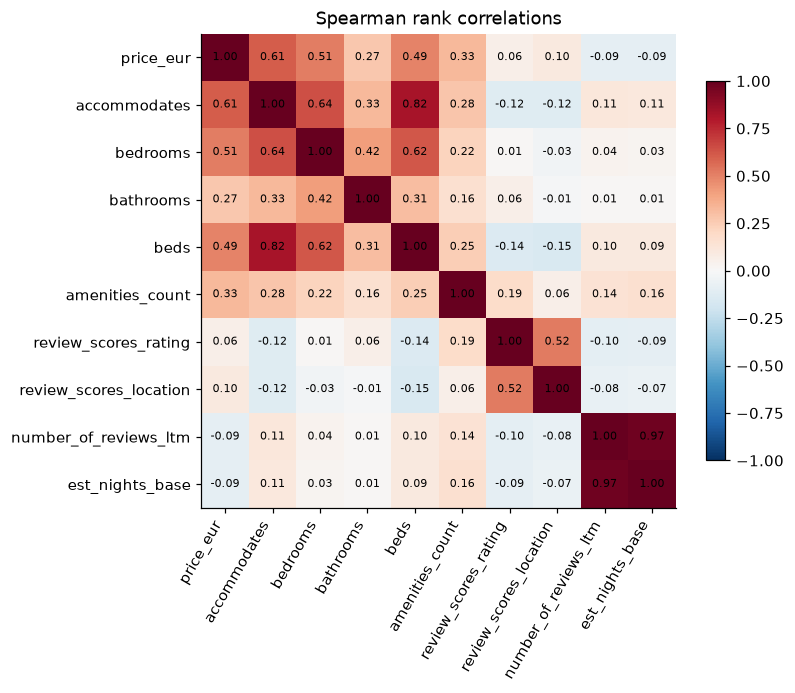

,spearman vs price
accommodates,0.61
bedrooms,0.51
beds,0.49
amenities_count,0.33
bathrooms,0.27
review_scores_location,0.10
review_scores_rating,0.06
est_nights_base,-0.09
number_of_reviews_ltm,-0.09


In [4]:
cols = ["price_eur", "accommodates", "bedrooms", "bathrooms", "beds", "amenities_count", "review_scores_rating", "review_scores_location", "number_of_reviews_ltm", "est_nights_base"]
corr = b[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.2, 5.6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(cols)), cols, rotation=60, ha="right"); ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)): ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, shrink=.8); ax.set_title("Spearman rank correlations"); save(fig, "03_correlations"); plt.show()
corr["price_eur"].drop("price_eur").sort_values(ascending=False).round(2).to_frame("spearman vs price")

**Takeaway.** Size drives price: guest capacity (rho 0.61), bedrooms (0.51) and beds (0.49) are the strongest correlates; amenities count is moderate (0.33) and bathrooms weaker (0.27).
Review scores are almost unrelated to price (0.06 rating, 0.10 location). Recent review count and estimated nights are very weakly *negative* (-0.09): busier listings are slightly cheaper,
a faint hint of the price-vs-occupancy trade-off that the V2 model will quantify. Correlation is not causation: location and size are confounded.

## 4. Price by district (entire homes) and map-ready summary

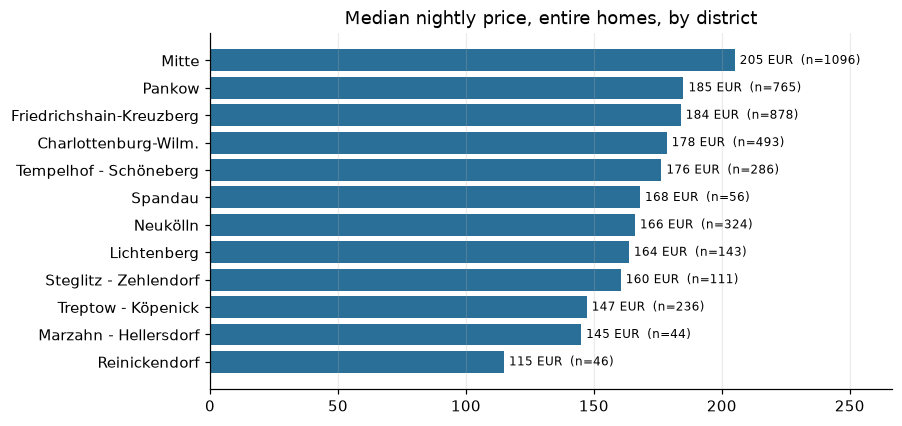

In [5]:
eh = b[b.room_type == "Entire home/apt"]
d = eh.groupby("district").price_eur.agg(["count", "median"]).sort_values("median")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(d.index, d["median"], color=BLUE)
for i, (n, m) in enumerate(zip(d["count"], d["median"])): ax.text(m + 2, i, f"{m:.0f} EUR  (n={n})", va="center", fontsize=8)
ax.set_xlim(0, d["median"].max() * 1.3); ax.set_title("Median nightly price, entire homes, by district"); ax.grid(axis="y", visible=False)
save(fig, "04_price_by_district"); plt.show()

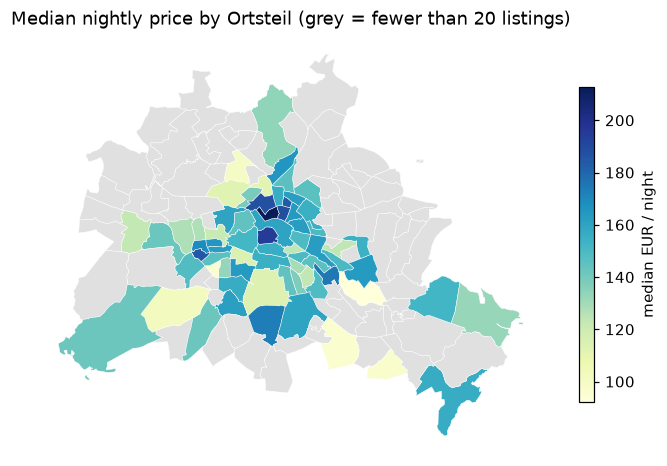

,district,neighbourhood,n_listings,median_price,median_est_revenue
3,Mitte,Brunnenstr. Süd,264,212.8,23213.0
25,Mitte,Regierungsviertel,83,194.5,30600.0
4,Pankow,Prenzlauer Berg Südwest,209,188.0,30832.0
5,Mitte,Brunnenstr. Nord,155,187.7,6055.0
38,Charlottenburg-Wilm.,Halensee,50,184.7,15839.0
16,Pankow,Helmholtzplatz,111,183.7,32816.0
67,Treptow - Köpenick,Plänterwald,20,175.0,32814.0
55,Tempelhof - Schöneberg,Mariendorf,24,173.2,4814.0


In [6]:
# Map: Ortsteil polygons from neighbourhoods.geojson coloured by median price (n >= 20 only; others grey).
geo = json.loads((ROOT / "data" / "raw" / "neighbourhoods.geojson").read_text(encoding="utf-8"))
ns = q("SELECT * FROM analysis.neighbourhood_summary").set_index(["district", "neighbourhood"])
polys, vals = [], []
for ft in geo["features"]:
    key = (ft["properties"]["neighbourhood_group"], ft["properties"]["neighbourhood"])
    v = ns.median_price.get(key, np.nan) if key in ns.index and ns.loc[key, "is_reliable_sample"] else np.nan
    g = ft["geometry"]; parts = g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]
    for part in parts: polys.append(np.array(part[0])); vals.append(v)
vals = np.array(vals, dtype=float)
fig, ax = plt.subplots(figsize=(7.5, 6.2))
cmap = plt.get_cmap("YlGnBu"); norm = plt.Normalize(np.nanmin(vals), np.nanmax(vals))
fc = [cmap(norm(v)) if not np.isnan(v) else (.88, .88, .88, 1) for v in vals]
pc = PolyCollection(polys, facecolors=fc, edgecolors="white", linewidths=.3)
ax.add_collection(pc); ax.autoscale(); ax.set_aspect(1/np.cos(np.radians(52.5))); ax.axis("off")
sm = plt.cm.ScalarMappable(cmap="YlGnBu", norm=plt.Normalize(np.nanmin(vals), np.nanmax(vals))); plt.colorbar(sm, ax=ax, shrink=.6, label="median EUR / night")
ax.set_title("Median nightly price by Ortsteil (grey = fewer than 20 listings)"); save(fig, "05_price_map"); plt.show()
ns.reset_index().sort_values("median_price", ascending=False).query("is_reliable_sample").head(8)[["district", "neighbourhood", "n_listings", "median_price", "median_est_revenue"]]

**Takeaway.** Central districts (Mitte, Pankow, Friedrichshain-Kreuzberg) are the most expensive; the outer north and east are cheapest. Within a district the spread is large
(see p25-p75 in `analysis.price_by_district_roomtype`), so district alone is a weak price predictor: size and room type matter as much.
Locations are anonymised to about 150 m, so Ortsteil-level aggregation is the right resolution.

## 5. Seasonality: reviews as a demand proxy

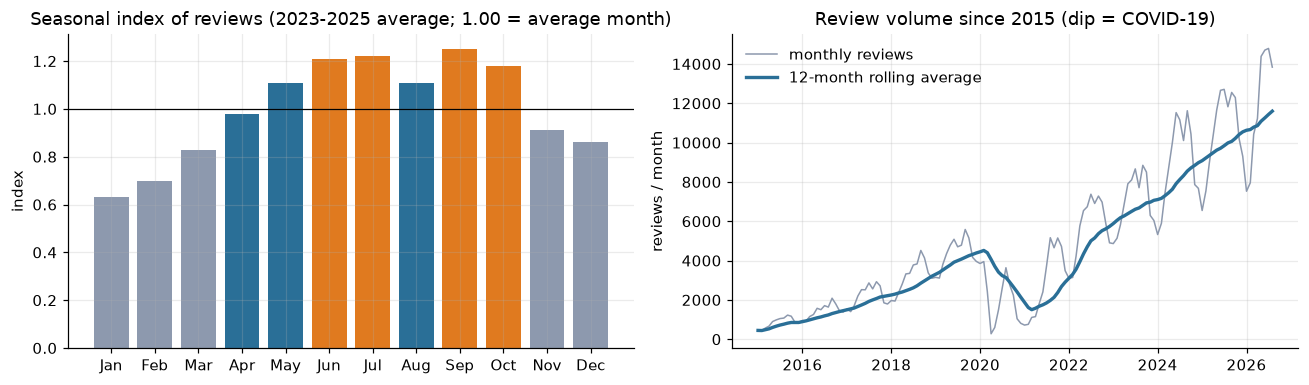

,0,1,2,3,4,5,6,7,8,9,10,11
month_name,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
seasonal_index,0.63,0.7,0.83,0.98,1.11,1.21,1.22,1.11,1.25,1.18,0.91,0.86
rank_busiest,12,11,10,7,5,3,2,6,1,4,8,9


In [7]:
si = q("SELECT * FROM analysis.seasonal_index ORDER BY month")
ms = q("SELECT * FROM analysis.monthly_review_series")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(si.month_name, si.seasonal_index, color=[ORANGE if v >= 1.15 else BLUE if v >= 0.95 else GREY for v in si.seasonal_index])
ax[0].axhline(1, color="k", lw=.8); ax[0].set(title="Seasonal index of reviews (2023-2025 average; 1.00 = average month)", ylabel="index")
ax[1].plot(pd.to_datetime(ms.month_start), ms.reviews, color=GREY, lw=1, label="monthly reviews")
ax[1].plot(pd.to_datetime(ms.month_start), ms.rolling_12m, color=BLUE, lw=2.2, label="12-month rolling average")
ax[1].set(title="Review volume since 2015 (dip = COVID-19)", ylabel="reviews / month"); ax[1].legend(frameon=False)
plt.tight_layout(); save(fig, "06_seasonality"); plt.show()
si[["month_name", "seasonal_index", "rank_busiest"]].T

**Takeaway.** Review activity is highest in September (index 1.25), July (1.22), June (1.21) and October (1.18), and lowest in January (0.63) and February (0.70).
Reviews are written after the stay, so the real demand peak is probably a few weeks earlier. The 2020-21 collapse and the strong recovery are visible.
**Limit:** this release has no calendar prices, so we can show *when demand is high* but not *how much hosts charge* in each month.

## 6. Forward calendar: booking pressure, events and a caveat

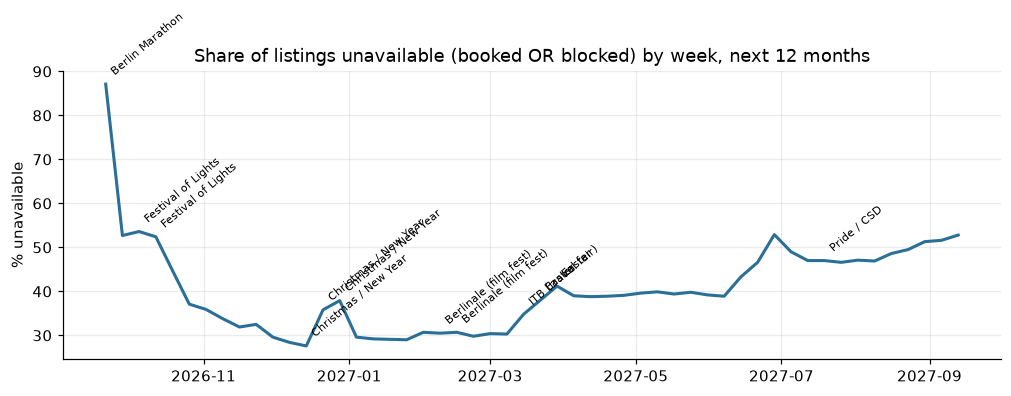

,event_name,window_is_indicative,event_unavailable_pct,other_days_same_months_pct,uplift_pp
0,Berlin Marathon,False,82.8,77.8,5.0
1,Festival of Lights,False,53.6,45.4,8.2
2,Christmas / New Year,False,36.9,29.0,7.9
3,Berlinale (film fest),False,30.7,30.2,0.5
4,ITB (travel fair),False,33.0,33.1,-0.1
5,Easter,False,38.3,33.1,5.2
6,Pride / CSD,False,47.0,48.5,-1.5


In [8]:
fw = q("SELECT * FROM analysis.forward_availability_weekly WHERE listing_days > 20000 ORDER BY week_start")
ev = q("SELECT * FROM analysis.forward_availability_events")
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(pd.to_datetime(fw.week_start), fw.unavailable_pct, color=BLUE, lw=2)
ax.set(title="Share of listings unavailable (booked OR blocked) by week, next 12 months", ylabel="% unavailable")
for r in fw.dropna(subset=["event_name"]).itertuples(): ax.annotate(r.event_name, (pd.to_datetime(r.week_start), r.unavailable_pct), fontsize=7, rotation=40, xytext=(2, 6), textcoords="offset points")
save(fig, "07_forward_availability"); plt.show()
ev[["event_name", "window_is_indicative", "event_unavailable_pct", "other_days_same_months_pct", "uplift_pp"]]

**Takeaway and caveat.** Nights close to the scrape date are much fuller than nights 9-12 months out, so this curve **mixes lead time with seasonality**:
do not read the high September values as seasonality. The event table compares event days with other days of the *same months* to reduce that bias:
Festival of Lights (+8.2 pp), Christmas/New Year (+7.9), Easter (+5.2) and the Marathon weekend (+5.0) show higher unavailability; Berlinale (+0.5), ITB (-0.1) and Pride (-1.5) show no uplift. Event dates were verified against official sources (23 Nov 2026) but organisers can change them,
and 'unavailable' includes host-blocked nights. Treat this as directional evidence, not a measured price premium.

## 7. Estimated occupancy and revenue (ESTIMATES)

Listings with zero reviews in last 12 months: 11.8% (the model assigns them 0 nights)


,low,base,high
count,6456.0,6456.0,6456.0
25%,3597.0,6323.0,7899.0
50%,12701.0,19632.0,21868.0
75%,27496.0,36465.0,39110.0
90%,45722.0,57881.0,61680.0
mean,19143.0,25715.0,27815.0


Top 10% of listings earn 33% of total estimated revenue; median listing 19,632 EUR/yr (base), reviewed-only median 22,695


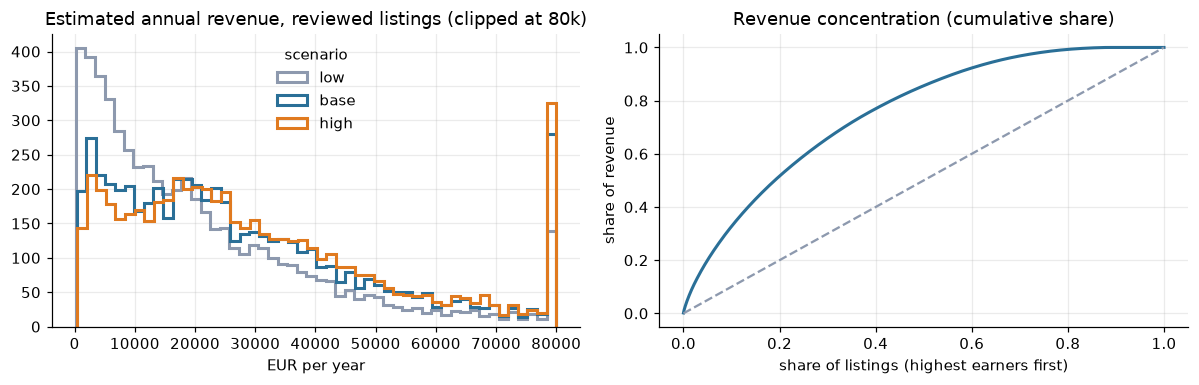

In [9]:
r = b.copy()
r["reviewed"] = r.number_of_reviews_ltm > 0
print(f"Listings with zero reviews in last 12 months: {(~r.reviewed).mean():.1%} (the model assigns them 0 nights)")
sc = pd.DataFrame({s: r[f"est_revenue_{s}"].describe(percentiles=[.25, .5, .75, .9]) for s in ["low", "base", "high"]}).loc[["count", "25%", "50%", "75%", "90%", "mean"]].round(0)
display(sc)
top = r.est_revenue_base.sort_values(ascending=False); cum = top.cumsum() / top.sum()
print(f"Top 10% of listings earn {cum.iloc[int(len(top)*.1)-1]:.0%} of total estimated revenue; median listing {r.est_revenue_base.median():,.0f} EUR/yr (base), reviewed-only median {r[r.reviewed].est_revenue_base.median():,.0f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for s, c in zip(["low", "base", "high"], [GREY, BLUE, ORANGE]):
    ax[0].hist(r[r.reviewed][f"est_revenue_{s}"].clip(upper=80000), bins=50, histtype="step", color=c, lw=2, label=s)
ax[0].set(title="Estimated annual revenue, reviewed listings (clipped at 80k)", xlabel="EUR per year"); ax[0].legend(title="scenario", frameon=False)
x = np.linspace(0, 1, len(top)); ax[1].plot(x, cum.values, color=BLUE, lw=2); ax[1].plot([0, 1], [0, 1], color=GREY, ls="--")
ax[1].set(title="Revenue concentration (cumulative share)", xlabel="share of listings (highest earners first)", ylabel="share of revenue")
plt.tight_layout(); save(fig, "08_revenue"); plt.show()

**Takeaway.** The mean estimated income (about 25.7k EUR/yr, base) is roughly 31% above the median (19.6k) and the top 10% of listings earn about a third of all estimated revenue, so a 'typical' host should plan on the median, not the mean.
The low scenario's median is about 35% below base and the high about 11% above (12.7k / 19.6k / 21.9k EUR), which is the honest uncertainty of a review-based occupancy model. Revenue here is *gross nights x today's price*, before platform fees, cleaning, taxes and costs, and zero-review listings are counted as 0 nights.

## 8. Supply, hosts and demand trend

,host_type,hosts,active_listings,share_of_listings_pct,entire_home_pct,median_price,median_est_revenue,share_of_est_revenue_pct,registration_number_pct
0,Single-listing host,2516,2516,39.0,69.2,139.3,18092.0,33.6,76.0
1,Small multi (2-3),608,1228,19.0,62.0,135.0,20400.0,19.3,50.2
2,Professional (4-10),292,1617,25.0,67.7,165.7,21959.0,28.1,19.4
3,Commercial (11+),59,1095,17.0,80.5,181.4,19917.0,19.0,4.9


,district,reviews,yoy_pct,growth_rank
0,Spandau,707,53.0,1
1,Charlottenburg-Wilm.,10444,25.3,2
2,Mitte,25456,20.0,3
3,Steglitz - Zehlendorf,1814,19.0,4
4,Treptow - Köpenick,2868,16.2,5
5,Tempelhof - Schöneberg,5976,13.6,6
6,Pankow,15097,12.5,7
7,Neukölln,6026,11.5,8
8,Friedrichshain-Kreuzberg,22183,11.3,9
9,Lichtenberg,2614,5.5,10


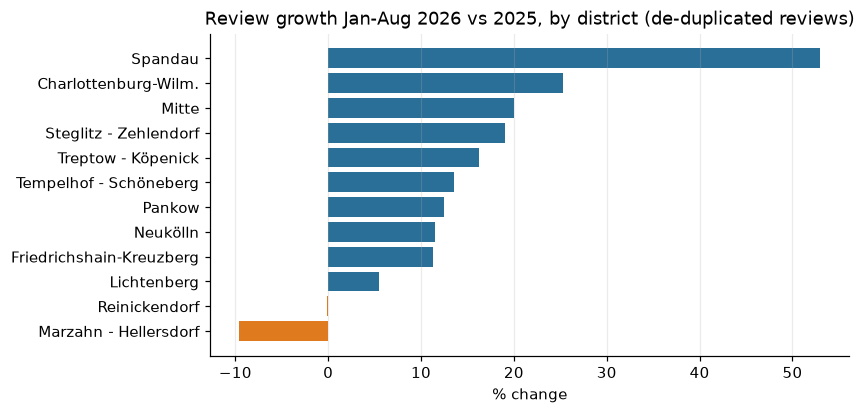

In [10]:
hs = q("SELECT * FROM analysis.multi_listing_hosts")
dt = q("SELECT * FROM analysis.review_demand_trends WHERE year_ytd_aug = 2026 ORDER BY growth_rank")
display(hs[["host_type", "hosts", "active_listings", "share_of_listings_pct", "entire_home_pct", "median_price", "median_est_revenue", "share_of_est_revenue_pct", "registration_number_pct"]])
display(dt[["district", "reviews", "yoy_pct", "growth_rank"]])
fig, ax = plt.subplots(figsize=(7.5, 3.8)); dd = dt.sort_values("yoy_pct")
ax.barh(dd.district, dd.yoy_pct, color=[BLUE if v >= 0 else ORANGE for v in dd.yoy_pct]); ax.set_title("Review growth Jan-Aug 2026 vs 2025, by district (de-duplicated reviews)"); ax.set_xlabel("% change"); ax.grid(axis="y", visible=False)
save(fig, "09_demand_growth"); plt.show()

**Takeaway.** Hosts with 4+ listings are about 10% of hosts (351 of 3,475) but 42% of benchmark listings. The share with a registration-number-like entry in the `license` field falls from 76% (single-listing hosts) to 4.9% (11+ listings);
this is descriptive only and **not a compliance check**. Review demand grew year on year in 10 of 12 districts (Reinickendorf flat, Marzahn-Hellersdorf -9.6%); Spandau's +53% rests on only 707 reviews.

## 9. Summary of findings for the memo
1. Define the market first: only ~52% of listings are priced short-stay.
2. Use medians; price is skewed. Entire homes in Mitte are the price ceiling, outer districts the floor.
3. Size and room type explain more of the price than district alone.
4. Demand peaks June-October and troughs January-February (reviews proxy); event uplift is directional.
5. Typical (median) income is about a quarter below the mean; the top decile earns about a third of estimated revenue.
6. All occupancy/revenue figures are estimates with a quantified low-high range.

**Next (V2):** dbt models + tests, a gradient-boosting price model compared honestly with a district x room-type median baseline, a revenue calculator and a 90-night-cap scenario.